# Time-Constrained Evaluation

This notebook compares a compute-bounded pipeline against time-limited
MILP baselines under two complementary protocols:

1. **Fixed budgets**: both methods are evaluated under budget caps
   such as `1s`, `2s`, `5s`, `10s`, ...
2. **Matched budgets**: each scenario's MILP budget is set equal to
   the observed pipeline wall-clock time on that scenario.

The main question is not only objective quality, but **time-constrained
feasibility**:

- Does the method return a feasible solution within the budget?
- If yes, how good is that solution relative to the reference MILP run?

In [1]:
import json
import math
import os
import pickle
import shutil
import sys
import time
from pathlib import Path
from types import SimpleNamespace
from typing import Any, Dict, List, Optional, Sequence, Tuple

_cwd = Path.cwd().resolve()
_repo_candidates = [_cwd, *_cwd.parents]
for _cand in list(_repo_candidates):
    _nested = _cand / "benchmark_milp_gnn"
    if (_nested / "src").exists():
        _repo_candidates.append(_nested)
for _cand in _repo_candidates:
    if (_cand / "src").exists():
        if str(_cand) not in sys.path:
            sys.path.insert(0, str(_cand))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm.auto import tqdm

from src.eval.metrics import build_comparison_dataframe, load_milp_reports
from src.eval.time_constrained_milp import (
    run_constrained_milp_with_guard as run_constrained_milp_with_guard_helper,
)

sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=0.85)

print(f"Python cwd: {Path.cwd().resolve()}")

Python cwd: C:\Users\coudr\OneDrive\projects\benchmark\benchmark_milp_gnn\notebooks


## 1. Configuration

In [2]:
def find_repo_path(start: Path) -> Path:
    start = start.resolve()
    candidates = [start, *start.parents]
    for cand in candidates:
        if (cand / "src").exists() and (cand / "outputs").exists():
            return cand
        nested = cand / "benchmark_milp_gnn"
        if (nested / "src").exists() and (nested / "outputs").exists():
            return nested
    raise RuntimeError("Could not locate benchmark_milp_gnn repository root from current working directory.")


REPO_PATH = find_repo_path(Path.cwd())
OUTPUT_DIR = REPO_PATH / "outputs" / "uc_jepa" / "personas_grid_milp_120_k1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PIPELINE_RESULTS_DIR = REPO_PATH / "outputs" / "uc_jepa" / "latent_time_budget_120_personas_k1"
PIPELINE_RESULTS_PATH = PIPELINE_RESULTS_DIR / "pipeline_eval_all_families.pkl"

TIME_CONSTRAINED_CACHE_PATH = OUTPUT_DIR / "time_constrained_milp_runs.pkl"
RERUN_TIME_CONSTRAINED_MILP = False
CLEAR_TIME_CONSTRAINED_CACHE = False
MAX_SCENARIOS_PER_FAMILY = None

FIXED_BUDGETS_SECONDS = [1.0, 2.0, 5.0, 10.0, 30.0, 60.0, 120.0]
MATCHED_BUDGET_SOURCE = "pipeline_solve_time"  # or "pipeline_first_candidate_time"
MIN_MATCHED_BUDGET_SECONDS = 0.25

SOLVER_NAME = "appsi_highs"
TEE_SOLVER = False
MILP_HARD_TIMEOUT_ENABLED = True
MILP_HARD_TIMEOUT_GRACE_SECONDS = 0.5

# Persona families. Keys MUST match the `family` field emitted by
# `evaluate_latent_pipeline` (see `_family_alias`), which for personas passes
# the directory name through unchanged.
FAMILIES = {
    "persona_vre_battery_scenarios": {
        "scenarios_dir": REPO_PATH / "outputs" / "persona_vre_battery_scenarios",
        "reports_dir": REPO_PATH / "outputs" / "persona_vre_battery_scenarios" / "reports",
    },
    "persona_network_operator_scenarios": {
        "scenarios_dir": REPO_PATH / "outputs" / "persona_network_operator_scenarios",
        "reports_dir": REPO_PATH / "outputs" / "persona_network_operator_scenarios" / "reports",
    },
    "persona_mathematician_scenarios": {
        "scenarios_dir": REPO_PATH / "outputs" / "persona_mathematician_scenarios",
        "reports_dir": REPO_PATH / "outputs" / "persona_mathematician_scenarios" / "reports",
    },
}

# Stable display order + colors used by every plot below. Defining this once
# (rather than hardcoding "low/medium/high" in every cell) means swapping
# personas only requires touching this block.
FAMILY_ORDER = list(FAMILIES.keys())
FAMILY_LABELS = {
    "persona_vre_battery_scenarios": "VRE+Battery",
    "persona_network_operator_scenarios": "Network Op.",
    "persona_mathematician_scenarios": "Mathematician",
}
FAMILY_COLORS = {
    "persona_vre_battery_scenarios": "#2ecc71",
    "persona_network_operator_scenarios": "#f39c12",
    "persona_mathematician_scenarios": "#e74c3c",
}

print(f"REPO_PATH = {REPO_PATH}")
print(f"PIPELINE_RESULTS_PATH exists: {PIPELINE_RESULTS_PATH.exists()}")
print(f"OUTPUT_DIR = {OUTPUT_DIR}")
print(f"FAMILY_ORDER = {FAMILY_ORDER}")
print(f"FIXED_BUDGETS_SECONDS = {FIXED_BUDGETS_SECONDS}")
print(f"MATCHED_BUDGET_SOURCE = {MATCHED_BUDGET_SOURCE}")
print(f"MILP_HARD_TIMEOUT_ENABLED = {MILP_HARD_TIMEOUT_ENABLED}")


REPO_PATH = C:\Users\coudr\OneDrive\projects\benchmark\benchmark_milp_gnn
PIPELINE_RESULTS_PATH exists: True
OUTPUT_DIR = C:\Users\coudr\OneDrive\projects\benchmark\benchmark_milp_gnn\outputs\uc_jepa\personas_grid_milp_120_k1
FAMILY_ORDER = ['persona_vre_battery_scenarios', 'persona_network_operator_scenarios', 'persona_mathematician_scenarios']
FIXED_BUDGETS_SECONDS = [1.0, 2.0, 5.0, 10.0, 30.0, 60.0, 120.0]
MATCHED_BUDGET_SOURCE = pipeline_solve_time
MILP_HARD_TIMEOUT_ENABLED = True


## 2. Helper Functions

In [5]:
def _scenario_key(family: str, scenario_id: str) -> Tuple[str, str]:
    return (str(family), str(scenario_id))


def _is_finite_number(value: Any) -> bool:
    try:
        value_f = float(value)
    except (TypeError, ValueError):
        return False
    return np.isfinite(value_f)


def _safe_float(value: Any, default: float = float("nan")) -> float:
    try:
        value_f = float(value)
    except (TypeError, ValueError):
        return default
    return value_f if np.isfinite(value_f) else default


def _safe_gap_pct(objective: Any, reference: Any) -> float:
    obj = _safe_float(objective)
    ref = _safe_float(reference)
    if not np.isfinite(obj) or not np.isfinite(ref):
        return float("nan")
    denom = max(abs(ref), 1e-9)
    return 100.0 * (obj - ref) / denom


def _termination_str(term: Any) -> str:
    if term is None:
        return ""
    if hasattr(term, "name"):
        return str(term.name)
    return str(term)


def _is_timeout_term(term: Any) -> bool:
    label = _termination_str(term).strip().lower()
    normalized = "".join(ch for ch in label if ch.isalnum())
    return normalized in {
        "maxtimelimit",
        "timelimit",
        "maxtime",
        "timelimitreached",
        "maxruntime",
        "maxiterations",
        "hardtimelimitkilled",
    }


def load_pipeline_results(path: Path) -> List[Dict[str, Any]]:
    with Path(path).open("rb") as f:
        payload = pickle.load(f)
    if not isinstance(payload, list):
        raise TypeError(f"Expected list payload in {path}, got {type(payload)!r}")
    return payload


def load_all_reference_milp_reports(families: Dict[str, Dict[str, Path]]) -> Dict[str, Dict[str, Any]]:
    all_reports: Dict[str, Dict[str, Any]] = {}
    for family, paths in families.items():
        family_reports = load_milp_reports(paths["reports_dir"])
        for scenario_id, report in family_reports.items():
            all_reports[f"{family}/{scenario_id}"] = report
    return all_reports


def select_scenarios(families: Dict[str, Dict[str, Path]], max_per_family: Optional[int] = None) -> List[Dict[str, Any]]:
    selected: List[Dict[str, Any]] = []
    for family, paths in families.items():
        scenario_paths = sorted(paths["scenarios_dir"].glob("scenario_*.json"))
        if max_per_family is not None:
            scenario_paths = scenario_paths[: int(max_per_family)]
        for scenario_path in scenario_paths:
            selected.append(
                {
                    "family": family,
                    "scenario_id": scenario_path.stem,
                    "scenario_path": scenario_path,
                    "reports_dir": paths["reports_dir"],
                }
            )
    return selected


def summarize_milp_run(
    payload: Dict[str, Any],
    *,
    family: str,
    scenario_id: str,
    criticality_index: float,
    reference_objective: float,
    reference_solve_time: float,
    budget_mode: str,
    budget_label: str,
    budget_seconds: float,
    matched_budget_source: str,
    end_to_end_seconds: float,
    pipeline_row: Optional[pd.Series],
) -> Dict[str, Any]:
    mip_summary = payload.get("mip")
    lp_summary = payload.get("lp")

    mip_obj_raw = _safe_float(getattr(mip_summary, "objective", float("nan")))
    milp_found_feasible = np.isfinite(mip_obj_raw) and not math.isinf(mip_obj_raw)
    milp_objective = mip_obj_raw if milp_found_feasible else float("nan")
    mip_term = _termination_str(getattr(mip_summary, "termination_condition", ""))
    mip_status = _termination_str(getattr(mip_summary, "solver_status", ""))
    milp_within_budget = bool(np.isfinite(float(end_to_end_seconds)) and float(end_to_end_seconds) <= float(budget_seconds) + 1e-9)
    milp_feasible_within_budget = bool(milp_found_feasible and milp_within_budget)

    row: Dict[str, Any] = {
        "scenario_id": scenario_id,
        "family": family,
        "criticality_index": criticality_index,
        "budget_mode": budget_mode,
        "budget_label": budget_label,
        "budget_seconds": float(budget_seconds),
        "matched_budget_source": matched_budget_source,
        "reference_milp_objective": reference_objective,
        "reference_milp_solve_time": reference_solve_time,
        "milp_found_feasible": bool(milp_found_feasible),
        "milp_within_budget": milp_within_budget,
        "milp_feasible_within_budget": milp_feasible_within_budget,
        "milp_optimal": mip_term.lower() == "optimal",
        "milp_timed_out": _is_timeout_term(mip_term),
        "milp_termination": mip_term,
        "milp_status": mip_status,
        "milp_objective": milp_objective,
        "milp_gap_vs_reference_pct": _safe_gap_pct(milp_objective, reference_objective),
        "milp_abs_gap_vs_reference_pct": abs(_safe_gap_pct(milp_objective, reference_objective))
        if np.isfinite(_safe_gap_pct(milp_objective, reference_objective))
        else float("nan"),
        "milp_mip_solve_time_s": _safe_float(getattr(mip_summary, "solve_seconds", float("nan"))),
        "milp_lp_relax_time_s": _safe_float(getattr(lp_summary, "solve_seconds", float("nan"))),
        "milp_end_to_end_time_s": float(end_to_end_seconds),
        "milp_feasibility_status": str(payload.get("feasibility_status", "")),
        "milp_scenario_classification": str(payload.get("scenario_classification", "")),
        "milp_exception_message": str(payload.get("exception_message", "")),
    }

    if pipeline_row is not None:
        pipeline_objective = _safe_float(pipeline_row.get("pipeline_objective", float("nan")))
        pipeline_gap = _safe_gap_pct(pipeline_objective, reference_objective)
        pipeline_time = _safe_float(pipeline_row.get("pipeline_solve_time", float("nan")))
        row.update(
            {
                "pipeline_found_feasible": bool(np.isfinite(pipeline_objective)),
                "pipeline_success_flag": bool(pipeline_row.get("success", False)),
                "pipeline_within_budget": bool(np.isfinite(pipeline_time) and pipeline_time <= float(budget_seconds) + 1e-9),
                "pipeline_feasible_within_budget": bool(np.isfinite(pipeline_objective) and np.isfinite(pipeline_time) and pipeline_time <= float(budget_seconds) + 1e-9),
                "pipeline_objective": pipeline_objective,
                "pipeline_gap_vs_reference_pct": pipeline_gap,
                "pipeline_abs_gap_vs_reference_pct": abs(pipeline_gap) if np.isfinite(pipeline_gap) else float("nan"),
                "pipeline_solve_time": pipeline_time,
                "pipeline_first_candidate_time": _safe_float(pipeline_row.get("pipeline_first_candidate_time", float("nan"))),
                "pipeline_best_status": str(pipeline_row.get("pipeline_best_status", "")),
                "pipeline_stage_reached": str(pipeline_row.get("pipeline_stage_reached", "")),
                "pipeline_n_candidates_evaluated": int(pipeline_row.get("pipeline_n_candidates_evaluated", 0) or 0),
                "pipeline_n_candidates_projected": int(pipeline_row.get("pipeline_n_candidates_projected", 0) or 0),
                "pipeline_fallback_used": bool(pipeline_row.get("pipeline_fallback_used", False)),
            }
        )
    return row


def build_budget_summary(
    df: pd.DataFrame,
    budget_mode: str,
) -> pd.DataFrame:
    scope = df[df["budget_mode"] == budget_mode].copy()
    if len(scope) == 0:
        return pd.DataFrame()

    # Use FAMILY_ORDER (defined in the configuration cell) for stable ordering;
    # this replaces the original hardcoded ["low", "medium", "high"] so the
    # notebook works for any family layout.
    rows: List[Dict[str, Any]] = []
    for family in [*FAMILY_ORDER, "ALL"]:
        fam_df = scope if family == "ALL" else scope[scope["family"] == family]
        if len(fam_df) == 0:
            continue
        for budget_seconds, budget_df in fam_df.groupby("budget_seconds", sort=True):
            both_feasible = budget_df["pipeline_feasible_within_budget"] & budget_df["milp_feasible_within_budget"]
            pipeline_better = (
                both_feasible
                & (budget_df["pipeline_abs_gap_vs_reference_pct"] <= budget_df["milp_abs_gap_vs_reference_pct"])
            )
            milp_better = (
                both_feasible
                & (budget_df["milp_abs_gap_vs_reference_pct"] < budget_df["pipeline_abs_gap_vs_reference_pct"])
            )
            rows.append(
                {
                    "family": family,
                    "budget_mode": budget_mode,
                    "budget_seconds": float(budget_seconds),
                    "n_scenarios": int(len(budget_df)),
                    "pipeline_feasible_rate_pct": float(100.0 * budget_df["pipeline_feasible_within_budget"].mean()),
                    "milp_feasible_rate_pct": float(100.0 * budget_df["milp_feasible_within_budget"].mean()),
                    "both_feasible_rate_pct": float(100.0 * both_feasible.mean()),
                    "pipeline_only_rate_pct": float(100.0 * (budget_df["pipeline_feasible_within_budget"] & ~budget_df["milp_feasible_within_budget"]).mean()),
                    "milp_only_rate_pct": float(100.0 * (~budget_df["pipeline_feasible_within_budget"] & budget_df["milp_feasible_within_budget"]).mean()),
                    "neither_feasible_rate_pct": float(100.0 * (~budget_df["pipeline_feasible_within_budget"] & ~budget_df["milp_feasible_within_budget"]).mean()),
                    "pipeline_median_abs_gap_pct": float(budget_df.loc[budget_df["pipeline_feasible_within_budget"], "pipeline_abs_gap_vs_reference_pct"].median()),
                    "milp_median_abs_gap_pct": float(budget_df.loc[budget_df["milp_feasible_within_budget"], "milp_abs_gap_vs_reference_pct"].median()),
                    "pipeline_better_gap_rate_pct": float(100.0 * pipeline_better.mean()),
                    "milp_better_gap_rate_pct": float(100.0 * milp_better.mean()),
                    "median_pipeline_time_s": float(budget_df["pipeline_solve_time"].median()),
                    "median_milp_end_to_end_time_s": float(budget_df["milp_end_to_end_time_s"].median()),
                }
            )
    # Preserve FAMILY_ORDER (followed by "ALL") in the output instead of
    # alphabetical sorting, which would mix "ALL" into the persona rows.
    family_rank = {name: idx for idx, name in enumerate([*FAMILY_ORDER, "ALL"])}
    out = pd.DataFrame(rows)
    out["__family_rank"] = out["family"].map(family_rank).fillna(len(family_rank))
    out = out.sort_values(["__family_rank", "budget_seconds"]).drop(columns="__family_rank").reset_index(drop=True)
    return out


def run_constrained_milp_with_guard(
    scenario_path: Path,
    budget_seconds: float,
) -> Tuple[Dict[str, Any], float]:
    return run_constrained_milp_with_guard_helper(
        scenario_path=scenario_path,
        budget_seconds=float(budget_seconds),
        solver_name=SOLVER_NAME,
        tee=TEE_SOLVER,
        capture_detail=False,
        warm_start_data=None,
        hard_timeout_enabled=MILP_HARD_TIMEOUT_ENABLED,
        hard_timeout_grace_s=float(MILP_HARD_TIMEOUT_GRACE_SECONDS),
    )


## 3. Load the Pipeline Results and Reference MILP Reports

In [6]:
if not PIPELINE_RESULTS_PATH.exists():
    raise FileNotFoundError(
        f"Pipeline results not found: {PIPELINE_RESULTS_PATH}. "
        "Run the compute-bounded pipeline experiment first."
    )

pipeline_results = load_pipeline_results(PIPELINE_RESULTS_PATH)
reference_milp_reports = load_all_reference_milp_reports(FAMILIES)
pipeline_df = build_comparison_dataframe(pipeline_results, reference_milp_reports)
pipeline_df["pipeline_found_feasible"] = pipeline_df["pipeline_objective"].replace([np.inf, -np.inf], np.nan).notna()
pipeline_df["pipeline_abs_gap_vs_reference_pct"] = pipeline_df["cost_gap_pct"].abs()

pipeline_keyed = {
    _scenario_key(row.family, row.scenario_id): row
    for row in pipeline_df.itertuples(index=False)
}

print(f"Loaded pipeline results: {len(pipeline_results)} scenarios")
print(f"Pipeline result families: {pipeline_df['family'].value_counts().to_dict()}")
print(f"Reference MILP reports: {len(reference_milp_reports)} family-scenario pairs")

display(
    pipeline_df[
        [
            "family",
            "scenario_id",
            "pipeline_solve_time",
            "pipeline_first_candidate_time",
            "pipeline_best_status",
            "pipeline_objective",
            "cost_gap_pct",
        ]
    ].head(12)
)

Loaded pipeline results: 300 scenarios
Pipeline result families: {'persona_mathematician_scenarios': 100, 'persona_network_operator_scenarios': 100, 'persona_vre_battery_scenarios': 100}
Reference MILP reports: 300 family-scenario pairs


,family,scenario_id,pipeline_solve_time,pipeline_first_candidate_time,pipeline_best_status,pipeline_objective,cost_gap_pct
0,persona_mathematician_scenarios,scenario_00001,29.247739,25.709325,projection_failed,inf,inf
1,persona_mathematician_scenarios,scenario_00002,26.168410,23.379700,projection_failed,inf,inf
2,persona_mathematician_scenarios,scenario_00003,23.109862,20.368021,projection_failed,inf,inf
3,persona_mathematician_scenarios,scenario_00004,26.087020,23.210255,projection_failed,inf,inf
4,persona_mathematician_scenarios,scenario_00005,23.740035,20.926253,projection_failed,inf,inf
5,persona_mathematician_scenarios,scenario_00006,21.330441,18.770389,projection_failed,inf,inf
6,persona_mathematician_scenarios,scenario_00007,31.013711,28.259581,repaired_feasible,1.752073e+09,34.482205
7,persona_mathematician_scenarios,scenario_00008,22.984992,20.156819,projection_failed,inf,inf
8,persona_mathematician_scenarios,scenario_00009,24.306763,21.486599,projection_failed,inf,inf
9,persona_mathematician_scenarios,scenario_00010,36.846447,33.916720,repaired_feasible,2.085127e+09,40.299349


## 4. Run or Load the Time-Constrained MILP Experiments

In [7]:
if CLEAR_TIME_CONSTRAINED_CACHE and TIME_CONSTRAINED_CACHE_PATH.exists():
    TIME_CONSTRAINED_CACHE_PATH.unlink()
    print(f"Deleted cache: {TIME_CONSTRAINED_CACHE_PATH}")

scenario_records = select_scenarios(FAMILIES, max_per_family=MAX_SCENARIOS_PER_FAMILY)
print(f"Scenario records selected: {len(scenario_records)}")

if RERUN_TIME_CONSTRAINED_MILP or not TIME_CONSTRAINED_CACHE_PATH.exists():
    constrained_runs: List[Dict[str, Any]] = []

    for record in tqdm(scenario_records, desc="Time-constrained MILP"):
        family = record["family"]
        scenario_id = record["scenario_id"]
        scenario_path = record["scenario_path"]
        pipeline_row = pipeline_keyed.get(_scenario_key(family, scenario_id))
        if pipeline_row is None:
            raise KeyError(f"Missing pipeline result for {family}/{scenario_id}")

        reference_objective = _safe_float(getattr(pipeline_row, "milp_objective", float("nan")))
        reference_solve_time = _safe_float(getattr(pipeline_row, "milp_solve_time", float("nan")))
        criticality_index = _safe_float(getattr(pipeline_row, "criticality_index", float("nan")))

        budgets: List[Tuple[str, str, float, str]] = []
        for budget_seconds in FIXED_BUDGETS_SECONDS:
            budgets.append(("fixed", f"fixed_{budget_seconds:g}s", float(budget_seconds), ""))

        matched_budget_seconds = max(
            MIN_MATCHED_BUDGET_SECONDS,
            _safe_float(getattr(pipeline_row, MATCHED_BUDGET_SOURCE, float("nan")), MIN_MATCHED_BUDGET_SECONDS),
        )
        budgets.append(
            (
                "matched_pipeline",
                f"matched_{MATCHED_BUDGET_SOURCE}",
                float(matched_budget_seconds),
                MATCHED_BUDGET_SOURCE,
            )
        )

        for budget_mode, budget_label, budget_seconds, matched_budget_source in budgets:
            payload, end_to_end_seconds = run_constrained_milp_with_guard(
                scenario_path=scenario_path,
                budget_seconds=float(budget_seconds),
            )
            constrained_runs.append(
                summarize_milp_run(
                    payload,
                    family=family,
                    scenario_id=scenario_id,
                    criticality_index=criticality_index,
                    reference_objective=reference_objective,
                    reference_solve_time=reference_solve_time,
                    budget_mode=budget_mode,
                    budget_label=budget_label,
                    budget_seconds=budget_seconds,
                    matched_budget_source=matched_budget_source,
                    end_to_end_seconds=end_to_end_seconds,
                    pipeline_row=pd.Series(pipeline_row._asdict()),
                )
            )

    with TIME_CONSTRAINED_CACHE_PATH.open("wb") as f:
        pickle.dump(constrained_runs, f)
    print(f"Saved constrained MILP cache: {TIME_CONSTRAINED_CACHE_PATH}")
else:
    with TIME_CONSTRAINED_CACHE_PATH.open("rb") as f:
        constrained_runs = pickle.load(f)
    print(f"Loaded constrained MILP cache: {TIME_CONSTRAINED_CACHE_PATH}")

tc_df = pd.DataFrame(constrained_runs)
tc_df.to_csv(OUTPUT_DIR / "time_constrained_milp_runs.csv", index=False)

print(f"time-constrained rows: {len(tc_df)}")
print(tc_df["budget_mode"].value_counts().to_dict())
display(tc_df.head(12))

Scenario records selected: 300
Loaded constrained MILP cache: C:\Users\coudr\OneDrive\projects\benchmark\benchmark_milp_gnn\outputs\uc_jepa\personas_grid_milp_120_k1\time_constrained_milp_runs.pkl
time-constrained rows: 2400
{'fixed': 2100, 'matched_pipeline': 300}


,scenario_id,family,criticality_index,budget_mode,budget_label,budget_seconds,matched_budget_source,reference_milp_objective,reference_milp_solve_time,milp_found_feasible,...,pipeline_objective,pipeline_gap_vs_reference_pct,pipeline_abs_gap_vs_reference_pct,pipeline_solve_time,pipeline_first_candidate_time,pipeline_best_status,pipeline_stage_reached,pipeline_n_candidates_evaluated,pipeline_n_candidates_projected,pipeline_fallback_used
0,scenario_00001,persona_vre_battery_scenarios,0.6262,fixed,fixed_1s,1.000000,,-2.641996e+07,7.844167,False,...,NaN,NaN,NaN,14.538915,12.159511,projection_failed,repair_1000_flips,1,1,False
1,scenario_00001,persona_vre_battery_scenarios,0.6262,fixed,fixed_2s,2.000000,,-2.641996e+07,7.844167,False,...,NaN,NaN,NaN,14.538915,12.159511,projection_failed,repair_1000_flips,1,1,False
2,scenario_00001,persona_vre_battery_scenarios,0.6262,fixed,fixed_5s,5.000000,,-2.641996e+07,7.844167,False,...,NaN,NaN,NaN,14.538915,12.159511,projection_failed,repair_1000_flips,1,1,False
3,scenario_00001,persona_vre_battery_scenarios,0.6262,fixed,fixed_10s,10.000000,,-2.641996e+07,7.844167,False,...,NaN,NaN,NaN,14.538915,12.159511,projection_failed,repair_1000_flips,1,1,False
4,scenario_00001,persona_vre_battery_scenarios,0.6262,fixed,fixed_30s,30.000000,,-2.641996e+07,7.844167,True,...,NaN,NaN,NaN,14.538915,12.159511,projection_failed,repair_1000_flips,1,1,False
5,scenario_00001,persona_vre_battery_scenarios,0.6262,fixed,fixed_60s,60.000000,,-2.641996e+07,7.844167,True,...,NaN,NaN,NaN,14.538915,12.159511,projection_failed,repair_1000_flips,1,1,False
6,scenario_00001,persona_vre_battery_scenarios,0.6262,fixed,fixed_120s,120.000000,,-2.641996e+07,7.844167,True,...,NaN,NaN,NaN,14.538915,12.159511,projection_failed,repair_1000_flips,1,1,False
7,scenario_00001,persona_vre_battery_scenarios,0.6262,matched_pipeline,matched_pipeline_solve_time,14.538915,pipeline_solve_time,-2.641996e+07,7.844167,False,...,NaN,NaN,NaN,14.538915,12.159511,projection_failed,repair_1000_flips,1,1,False
8,scenario_00002,persona_vre_battery_scenarios,0.6251,fixed,fixed_1s,1.000000,,-4.373613e+07,4.771667,False,...,NaN,NaN,NaN,14.643226,12.271310,projection_failed,repair_1000_flips,1,1,False
9,scenario_00002,persona_vre_battery_scenarios,0.6251,fixed,fixed_2s,2.000000,,-4.373613e+07,4.771667,False,...,NaN,NaN,NaN,14.643226,12.271310,projection_failed,repair_1000_flips,1,1,False


## 5. Fixed-Budget Comparison

,family,budget_mode,budget_seconds,n_scenarios,pipeline_feasible_rate_pct,milp_feasible_rate_pct,both_feasible_rate_pct,pipeline_only_rate_pct,milp_only_rate_pct,neither_feasible_rate_pct,pipeline_median_abs_gap_pct,milp_median_abs_gap_pct,pipeline_better_gap_rate_pct,milp_better_gap_rate_pct,median_pipeline_time_s,median_milp_end_to_end_time_s
0,persona_vre_battery_scenarios,fixed,1.0,100,0.000,0.000,0.000,0.000,0.000,100.000,NaN,NaN,0.0,0.000,13.096,1.025
1,persona_vre_battery_scenarios,fixed,2.0,100,0.000,0.000,0.000,0.000,0.000,100.000,NaN,NaN,0.0,0.000,13.096,2.027
2,persona_vre_battery_scenarios,fixed,5.0,100,0.000,0.000,0.000,0.000,0.000,100.000,NaN,NaN,0.0,0.000,13.096,5.027
3,persona_vre_battery_scenarios,fixed,10.0,100,27.000,0.000,0.000,27.000,0.000,73.000,0.934,NaN,0.0,0.000,13.096,10.026
4,persona_vre_battery_scenarios,fixed,30.0,100,52.000,100.000,52.000,0.000,48.000,0.000,0.354,0.0,0.0,52.000,13.096,14.350
5,persona_vre_battery_scenarios,fixed,60.0,100,52.000,100.000,52.000,0.000,48.000,0.000,0.354,0.0,0.0,52.000,13.096,14.311
6,persona_vre_battery_scenarios,fixed,120.0,100,52.000,100.000,52.000,0.000,48.000,0.000,0.354,0.0,0.0,52.000,13.096,14.289
7,persona_network_operator_scenarios,fixed,1.0,100,0.000,0.000,0.000,0.000,0.000,100.000,NaN,NaN,0.0,0.000,35.350,1.025
8,persona_network_operator_scenarios,fixed,2.0,100,0.000,0.000,0.000,0.000,0.000,100.000,NaN,NaN,0.0,0.000,35.350,2.025
9,persona_network_operator_scenarios,fixed,5.0,100,0.000,0.000,0.000,0.000,0.000,100.000,NaN,NaN,0.0,0.000,35.350,5.026


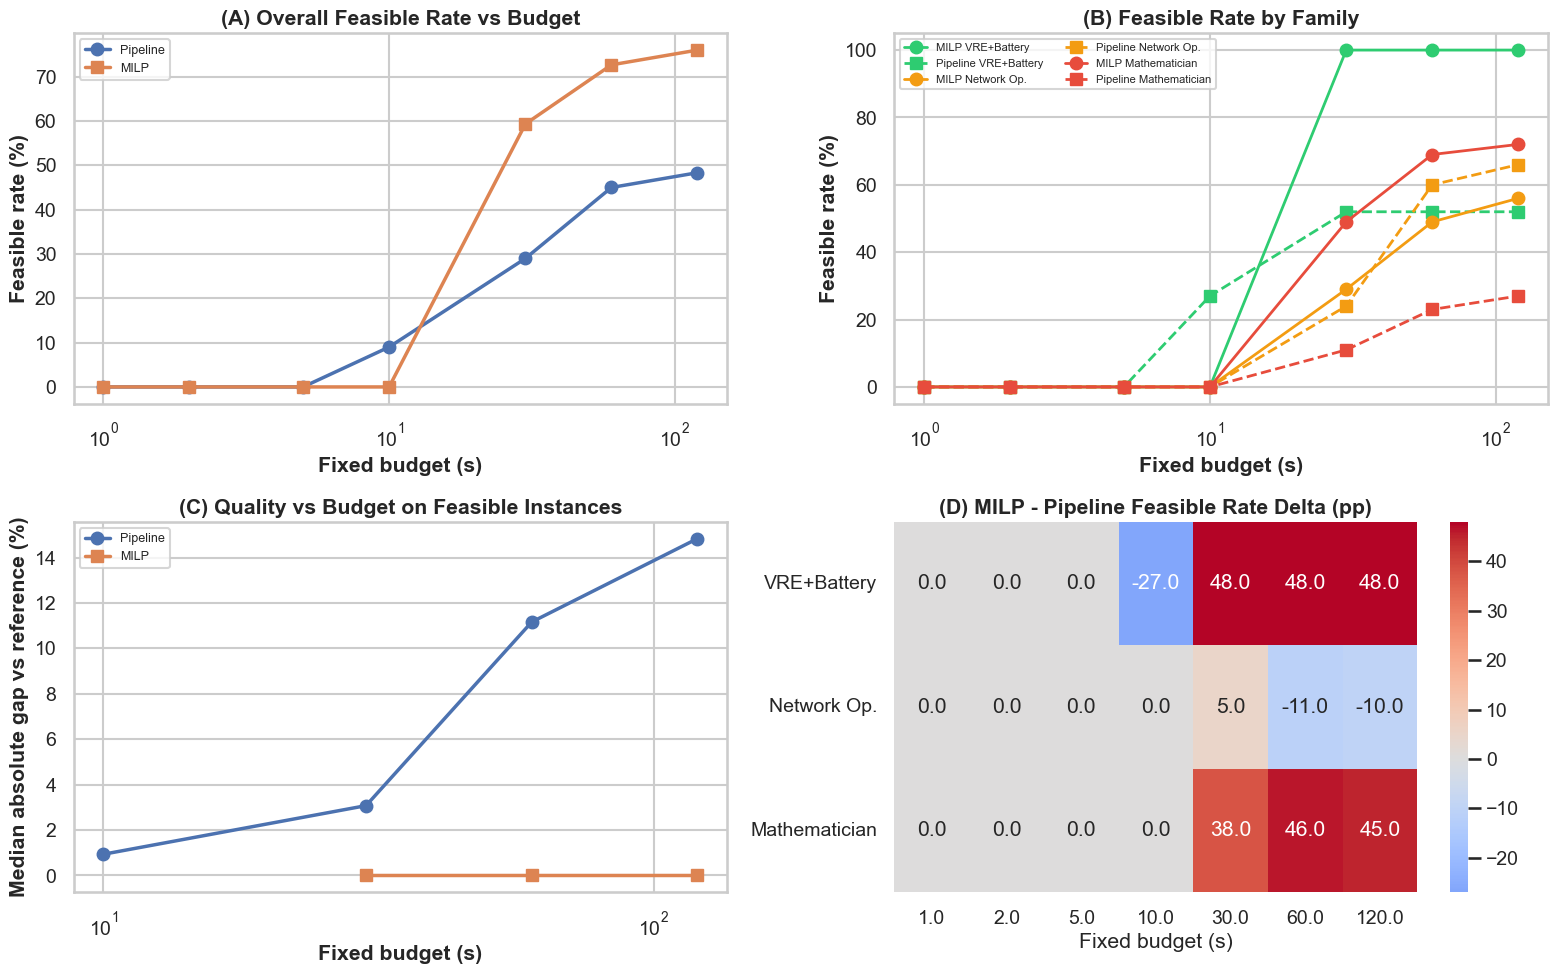

In [8]:
fixed_summary = build_budget_summary(tc_df, budget_mode="fixed")
display(fixed_summary.round(3))

fixed_all = fixed_summary[fixed_summary["family"] == "ALL"].copy()
fixed_family = fixed_summary[fixed_summary["family"] != "ALL"].copy()

# Active families = those that actually have rows (intersection of FAMILY_ORDER
# and what's present in tc_df). This keeps plots robust if a persona is missing.
active_families = [f for f in FAMILY_ORDER if (fixed_family["family"] == f).any()]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

ax = axes[0, 0]
ax.plot(fixed_all["budget_seconds"], fixed_all["pipeline_feasible_rate_pct"], marker="o", lw=2.5, label="Pipeline")
ax.plot(fixed_all["budget_seconds"], fixed_all["milp_feasible_rate_pct"], marker="s", lw=2.5, label="MILP")
ax.set_xscale("log")
ax.set_xlabel("Fixed budget (s)", fontweight="bold")
ax.set_ylabel("Feasible rate (%)", fontweight="bold")
ax.set_title("(A) Overall Feasible Rate vs Budget", fontweight="bold")
ax.legend(fontsize=9)

ax = axes[0, 1]
for family in active_families:
    fam_color = FAMILY_COLORS.get(family, "#7f7f7f")
    fam_label = FAMILY_LABELS.get(family, family)
    fam_df = fixed_family[fixed_family["family"] == family]
    if len(fam_df) == 0:
        continue
    ax.plot(
        fam_df["budget_seconds"],
        fam_df["milp_feasible_rate_pct"],
        marker="o",
        lw=2,
        color=fam_color,
        label=f"MILP {fam_label}",
    )
    ax.plot(
        fam_df["budget_seconds"],
        fam_df["pipeline_feasible_rate_pct"],
        marker="s",
        lw=2,
        linestyle="--",
        color=fam_color,
        label=f"Pipeline {fam_label}",
    )
ax.set_xscale("log")
ax.set_xlabel("Fixed budget (s)", fontweight="bold")
ax.set_ylabel("Feasible rate (%)", fontweight="bold")
ax.set_title("(B) Feasible Rate by Family", fontweight="bold")
ax.legend(fontsize=8, ncol=2)

ax = axes[1, 0]
ax.plot(fixed_all["budget_seconds"], fixed_all["pipeline_median_abs_gap_pct"], marker="o", lw=2.5, label="Pipeline")
ax.plot(fixed_all["budget_seconds"], fixed_all["milp_median_abs_gap_pct"], marker="s", lw=2.5, label="MILP")
ax.set_xscale("log")
ax.set_xlabel("Fixed budget (s)", fontweight="bold")
ax.set_ylabel("Median absolute gap vs reference (%)", fontweight="bold")
ax.set_title("(C) Quality vs Budget on Feasible Instances", fontweight="bold")
ax.legend(fontsize=9)

ax = axes[1, 1]
heatmap_df = (
    fixed_family.assign(feasible_rate_delta_pct=lambda x: x["milp_feasible_rate_pct"] - x["pipeline_feasible_rate_pct"])
    .pivot(index="family", columns="budget_seconds", values="feasible_rate_delta_pct")
    .reindex(index=active_families)
)
if not heatmap_df.empty:
    heatmap_labels = [FAMILY_LABELS.get(idx, idx) for idx in heatmap_df.index]
    sns.heatmap(heatmap_df, annot=True, fmt=".1f", cmap="coolwarm", center=0.0, ax=ax,
                yticklabels=heatmap_labels)
else:
    ax.text(0.5, 0.5, "No family data", ha="center", va="center", transform=ax.transAxes)
ax.set_title("(D) MILP - Pipeline Feasible Rate Delta (pp)", fontweight="bold")
ax.set_xlabel("Fixed budget (s)")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_fixed_budget_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## 6. Matched-Budget Comparison

,family,budget_mode,budget_seconds,n_scenarios,pipeline_feasible_rate_pct,milp_feasible_rate_pct,both_feasible_rate_pct,pipeline_only_rate_pct,milp_only_rate_pct,neither_feasible_rate_pct,pipeline_median_abs_gap_pct,milp_median_abs_gap_pct,pipeline_better_gap_rate_pct,milp_better_gap_rate_pct,median_pipeline_time_s,median_milp_end_to_end_time_s
0,persona_vre_battery_scenarios,matched_pipeline,5.476,1,100.0,0.0,0.0,100.0,0.0,0.0,0.000,NaN,0.0,0.0,5.476,5.499
1,persona_vre_battery_scenarios,matched_pipeline,5.803,1,100.0,0.0,0.0,100.0,0.0,0.0,0.934,NaN,0.0,0.0,5.803,5.836
2,persona_vre_battery_scenarios,matched_pipeline,5.982,1,100.0,0.0,0.0,100.0,0.0,0.0,3.390,NaN,0.0,0.0,5.982,5.999
3,persona_vre_battery_scenarios,matched_pipeline,6.516,1,100.0,0.0,0.0,100.0,0.0,0.0,0.701,NaN,0.0,0.0,6.516,6.538
4,persona_vre_battery_scenarios,matched_pipeline,6.558,1,100.0,0.0,0.0,100.0,0.0,0.0,0.021,NaN,0.0,0.0,6.558,6.584
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,ALL,matched_pipeline,120.033,1,0.0,0.0,0.0,0.0,0.0,100.0,NaN,NaN,0.0,0.0,120.033,120.067
596,ALL,matched_pipeline,120.034,1,0.0,100.0,0.0,0.0,100.0,0.0,NaN,0.0,0.0,0.0,120.034,58.303
597,ALL,matched_pipeline,120.035,1,0.0,0.0,0.0,0.0,0.0,100.0,NaN,NaN,0.0,0.0,120.035,120.045
598,ALL,matched_pipeline,120.036,1,0.0,0.0,0.0,0.0,0.0,100.0,NaN,NaN,0.0,0.0,120.036,120.066


,family,matched_outcome,count
0,persona_mathematician_scenarios,both_feasible,7
1,persona_mathematician_scenarios,milp_only,9
2,persona_mathematician_scenarios,neither,64
3,persona_mathematician_scenarios,pipeline_only,20
4,persona_network_operator_scenarios,both_feasible,13
5,persona_network_operator_scenarios,milp_only,5
6,persona_network_operator_scenarios,neither,29
7,persona_network_operator_scenarios,pipeline_only,53
8,persona_vre_battery_scenarios,both_feasible,18
9,persona_vre_battery_scenarios,milp_only,19


,family,n_scenarios,pipeline_feasible_rate_pct,milp_feasible_rate_pct,pipeline_median_abs_gap_pct,milp_median_abs_gap_pct,median_matched_budget_s
0,persona_vre_battery_scenarios,100,52.0,37.0,0.354,0.0,13.096
1,persona_network_operator_scenarios,100,66.0,18.0,20.856,0.0,35.350
2,persona_mathematician_scenarios,100,27.0,16.0,291.251,0.0,22.748


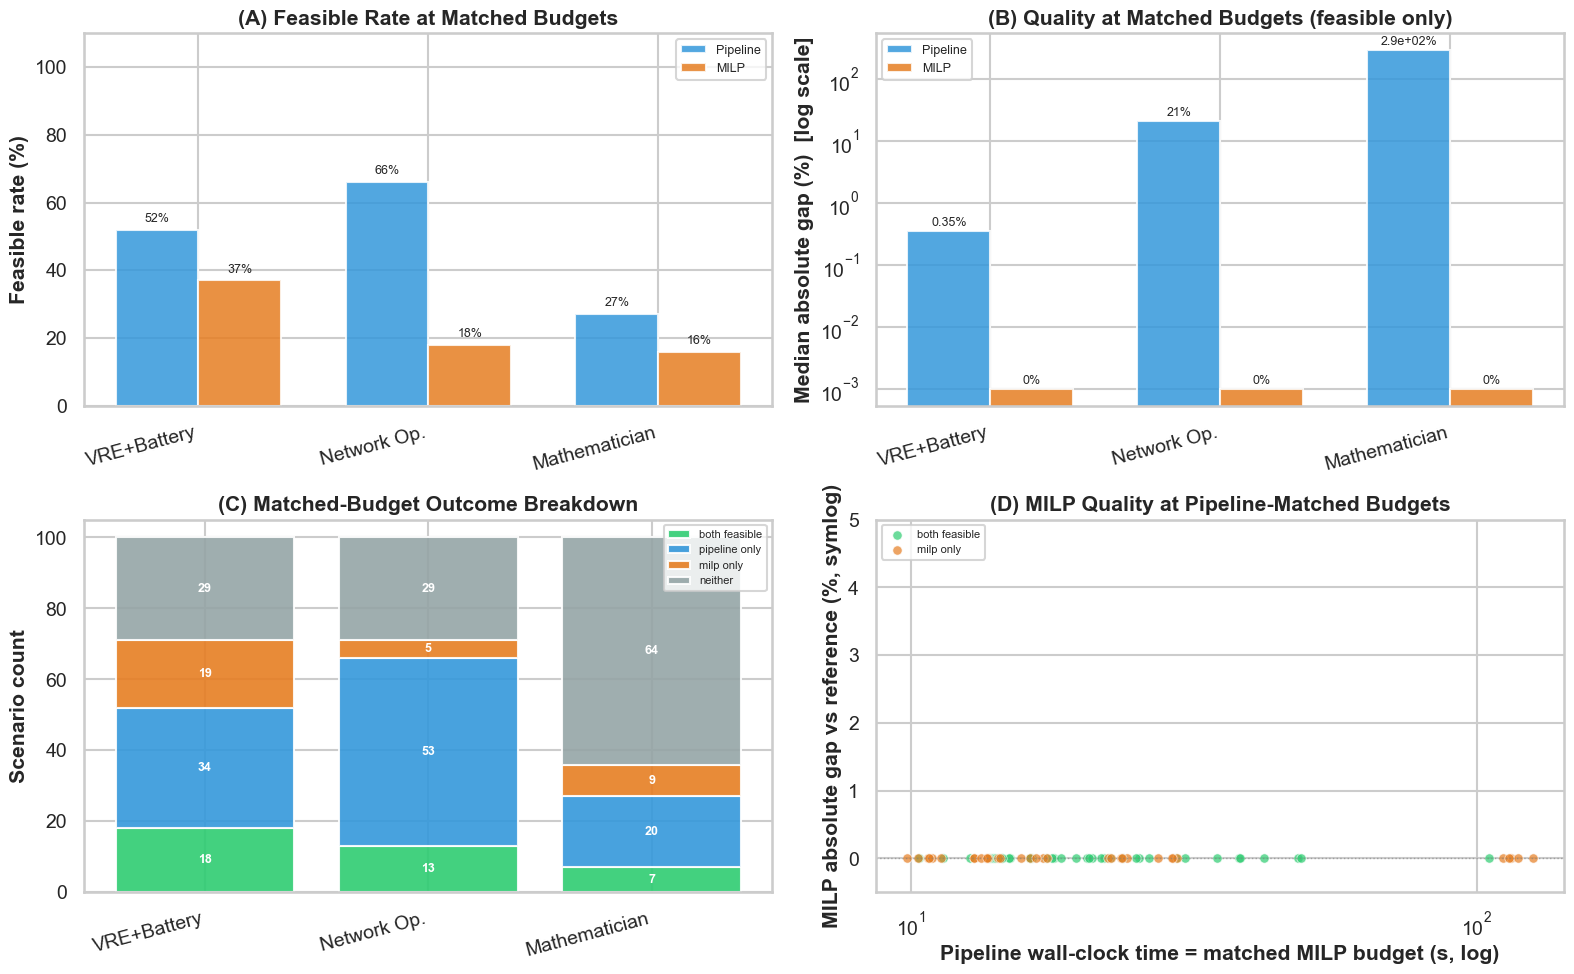

In [10]:
matched_summary = build_budget_summary(tc_df, budget_mode="matched_pipeline")
display(matched_summary.round(3))

matched_df = tc_df[tc_df["budget_mode"] == "matched_pipeline"].copy()

def _matched_outcome(row: pd.Series) -> str:
    pipe_ok = bool(row["pipeline_feasible_within_budget"])
    milp_ok = bool(row["milp_feasible_within_budget"])
    if pipe_ok and milp_ok:
        return "both_feasible"
    if pipe_ok and not milp_ok:
        return "pipeline_only"
    if milp_ok and not pipe_ok:
        return "milp_only"
    return "neither"


matched_df["matched_outcome"] = matched_df.apply(_matched_outcome, axis=1)
matched_counts = (
    matched_df.groupby(["family", "matched_outcome"])
    .size()
    .rename("count")
    .reset_index()
)
display(matched_counts)

# Active families for the plots in this cell.
active_families_matched = [f for f in FAMILY_ORDER if (matched_df["family"] == f).any()]
active_labels_matched = [FAMILY_LABELS.get(f, f) for f in active_families_matched]

# Aggregate to ONE row per family directly from matched_df (matched_summary
# has one row per distinct matched-budget, ~one per scenario, which would
# render as hundreds of bars in panels A/B).
def _per_family_matched_stats(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for fam in active_families_matched:
        sub = df[df["family"] == fam]
        if len(sub) == 0:
            continue
        pipe_feas = sub["pipeline_feasible_within_budget"].astype(bool)
        milp_feas = sub["milp_feasible_within_budget"].astype(bool)
        rows.append({
            "family": fam,
            "n_scenarios": int(len(sub)),
            "pipeline_feasible_rate_pct": 100.0 * pipe_feas.mean(),
            "milp_feasible_rate_pct": 100.0 * milp_feas.mean(),
            "pipeline_median_abs_gap_pct": float(sub.loc[pipe_feas, "pipeline_abs_gap_vs_reference_pct"].median()),
            "milp_median_abs_gap_pct": float(sub.loc[milp_feas, "milp_abs_gap_vs_reference_pct"].median()),
            "median_matched_budget_s": float(sub["budget_seconds"].median()),
        })
    return pd.DataFrame(rows)


per_family_stats = _per_family_matched_stats(matched_df)
display(per_family_stats.round(3))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

x = np.arange(len(per_family_stats))
width = 0.36

ax = axes[0, 0]
ax.bar(x - width / 2, per_family_stats["pipeline_feasible_rate_pct"], width=width, label="Pipeline", color="#3498db", alpha=0.85)
ax.bar(x + width / 2, per_family_stats["milp_feasible_rate_pct"], width=width, label="MILP", color="#e67e22", alpha=0.85)
for xi, (pp, mp) in enumerate(zip(per_family_stats["pipeline_feasible_rate_pct"], per_family_stats["milp_feasible_rate_pct"])):
    ax.text(xi - width / 2, pp + 1.5, f"{pp:.0f}%", ha="center", va="bottom", fontsize=9)
    ax.text(xi + width / 2, mp + 1.5, f"{mp:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(active_labels_matched, rotation=15, ha="right")
ax.set_ylim(0, 110)
ax.set_ylabel("Feasible rate (%)", fontweight="bold")
ax.set_title("(A) Feasible Rate at Matched Budgets", fontweight="bold")
ax.legend(fontsize=9, loc="upper right")

ax = axes[0, 1]
# Median gap can span many orders of magnitude (0.3% to 1700% across personas);
# log scale + value labels makes the plot readable instead of saturated.
gap_pipe = per_family_stats["pipeline_median_abs_gap_pct"].fillna(0.0).clip(lower=1e-3)
gap_milp = per_family_stats["milp_median_abs_gap_pct"].fillna(0.0).clip(lower=1e-3)
ax.bar(x - width / 2, gap_pipe, width=width, label="Pipeline", color="#3498db", alpha=0.85)
ax.bar(x + width / 2, gap_milp, width=width, label="MILP", color="#e67e22", alpha=0.85)
for xi, (gp, gm, raw_p, raw_m) in enumerate(zip(
    gap_pipe, gap_milp,
    per_family_stats["pipeline_median_abs_gap_pct"],
    per_family_stats["milp_median_abs_gap_pct"],
)):
    p_label = "n/a" if not np.isfinite(raw_p) else f"{raw_p:.2g}%"
    m_label = "n/a" if not np.isfinite(raw_m) else f"{raw_m:.2g}%"
    ax.text(xi - width / 2, gp * 1.08, p_label, ha="center", va="bottom", fontsize=9)
    ax.text(xi + width / 2, gm * 1.08, m_label, ha="center", va="bottom", fontsize=9)
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(active_labels_matched, rotation=15, ha="right")
ax.set_ylabel("Median absolute gap (%)  [log scale]", fontweight="bold")
ax.set_title("(B) Quality at Matched Budgets (feasible only)", fontweight="bold")
ax.legend(fontsize=9, loc="upper left")

ax = axes[1, 0]
outcome_order = ["both_feasible", "pipeline_only", "milp_only", "neither"]
outcome_colors = {
    "both_feasible": "#2ecc71",
    "pipeline_only": "#3498db",
    "milp_only": "#e67e22",
    "neither": "#95a5a6",
}
stacked = (
    matched_counts.pivot(index="family", columns="matched_outcome", values="count")
    .fillna(0.0)
    .reindex(index=active_families_matched)
)
bottom = np.zeros(len(stacked))
for outcome in outcome_order:
    vals = stacked.get(outcome, pd.Series(0.0, index=stacked.index)).to_numpy(dtype=float)
    ax.bar(
        np.arange(len(stacked)),
        vals,
        bottom=bottom,
        color=outcome_colors[outcome],
        alpha=0.9,
        label=outcome.replace("_", " "),
    )
    # Annotate non-zero segments inside the bar.
    for xi, v in enumerate(vals):
        if v >= 5:
            ax.text(xi, bottom[xi] + v / 2, f"{int(v)}", ha="center", va="center",
                    fontsize=9, color="white", fontweight="bold")
    bottom += vals
ax.set_xticks(np.arange(len(stacked)))
ax.set_xticklabels(active_labels_matched, rotation=15, ha="right")
ax.set_ylabel("Scenario count", fontweight="bold")
ax.set_title("(C) Matched-Budget Outcome Breakdown", fontweight="bold")
ax.legend(fontsize=8, loc="upper right")

ax = axes[1, 1]
# Panel D: MILP gap vs pipeline matched budget. Most matched budgets are large
# enough for HiGHS to reach the unconstrained optimum, so MILP gap clusters at
# ~0%. We show this with a symlog y-axis (so 0% is readable AND the long tail
# of bad MILP solves stays visible) and slight horizontal jitter so overlapping
# points don't collapse into a single line.
scatter_palette = {
    "both_feasible": "#2ecc71",
    "pipeline_only": "#3498db",
    "milp_only": "#e67e22",
    "neither": "#95a5a6",
}
rng = np.random.default_rng(0)
for outcome, sub in matched_df.groupby("matched_outcome"):
    if len(sub) == 0:
        continue
    times = sub["pipeline_solve_time"].astype(float).to_numpy()
    gaps = sub["milp_abs_gap_vs_reference_pct"].astype(float).to_numpy()
    finite = np.isfinite(times) & np.isfinite(gaps)
    if not finite.any():
        continue
    # Multiplicative log-jitter on x to spread overlapping markers.
    jitter = rng.uniform(0.92, 1.08, size=finite.sum())
    ax.scatter(
        times[finite] * jitter,
        gaps[finite],
        s=45,
        alpha=0.7,
        color=scatter_palette.get(outcome, "#7f7f7f"),
        edgecolors="white",
        linewidth=0.6,
        label=outcome.replace("_", " "),
    )
ax.set_xscale("log")
# symlog with linthresh=1 so 0% gap is plotted distinctly and outliers >100%
# don't compress everything else.
gap_max = float(np.nanmax(matched_df["milp_abs_gap_vs_reference_pct"].replace([np.inf, -np.inf], np.nan))) if len(matched_df) else 0.0
if np.isfinite(gap_max) and gap_max > 1.0:
    ax.set_yscale("symlog", linthresh=1.0)
    ax.set_ylim(-0.5, max(gap_max * 1.5, 10.0))
else:
    ax.set_ylim(-0.5, 5.0)
ax.axhline(0.0, color="grey", linestyle=":", linewidth=1, alpha=0.6)
ax.set_xlabel("Pipeline wall-clock time = matched MILP budget (s, log)", fontweight="bold")
ax.set_ylabel("MILP absolute gap vs reference (%, symlog)", fontweight="bold")
ax.set_title("(D) MILP Quality at Pipeline-Matched Budgets", fontweight="bold")
ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_matched_budget_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. Scenario-Level Diagnostics

In [11]:
matched_df = tc_df[tc_df["budget_mode"] == "matched_pipeline"].copy()
matched_df["matched_outcome"] = matched_df.apply(
    lambda row: (
        "both_feasible" if row["pipeline_feasible_within_budget"] and row["milp_feasible_within_budget"]
        else "pipeline_only" if row["pipeline_feasible_within_budget"] and not row["milp_feasible_within_budget"]
        else "milp_only" if row["milp_feasible_within_budget"] and not row["pipeline_feasible_within_budget"]
        else "neither"
    ),
    axis=1,
)

pipeline_only_cases = matched_df[matched_df["matched_outcome"] == "pipeline_only"].copy()
milp_only_cases = matched_df[matched_df["matched_outcome"] == "milp_only"].copy()
both_feasible_cases = matched_df[matched_df["matched_outcome"] == "both_feasible"].copy()
if len(both_feasible_cases):
    both_feasible_cases["pipeline_minus_milp_abs_gap_pct"] = (
        both_feasible_cases["pipeline_abs_gap_vs_reference_pct"]
        - both_feasible_cases["milp_abs_gap_vs_reference_pct"]
    )

display_cols = [
    "family",
    "scenario_id",
    "criticality_index",
    "budget_seconds",
    "pipeline_solve_time",
    "pipeline_best_status",
    "pipeline_stage_reached",
    "pipeline_abs_gap_vs_reference_pct",
    "milp_feasible_within_budget",
    "milp_termination",
    "milp_abs_gap_vs_reference_pct",
]

print("Pipeline feasible, MILP infeasible at matched budget:")
display(pipeline_only_cases[display_cols].sort_values(["family", "budget_seconds"], ascending=[True, False]).head(25).round(3))

print("MILP feasible, pipeline infeasible at matched budget:")
display(milp_only_cases[display_cols].sort_values(["family", "budget_seconds"], ascending=[True, False]).head(25).round(3))

if len(both_feasible_cases):
    print("Largest gap disagreements when both are feasible:")
    display(
        both_feasible_cases[
            display_cols + ["pipeline_minus_milp_abs_gap_pct"]
        ]
        .sort_values("pipeline_minus_milp_abs_gap_pct", ascending=False)
        .head(25)
        .round(3)
    )

Pipeline feasible, MILP infeasible at matched budget:


,family,scenario_id,criticality_index,budget_seconds,pipeline_solve_time,pipeline_best_status,pipeline_stage_reached,pipeline_abs_gap_vs_reference_pct,milp_feasible_within_budget,milp_termination,milp_abs_gap_vs_reference_pct
2391,persona_mathematician_scenarios,scenario_00099,0.483,114.844,114.844,repaired_feasible,repair_1000_flips,222.018,False,hard_time_limit_killed,NaN
1751,persona_mathematician_scenarios,scenario_00019,0.493,102.716,102.716,repaired_feasible,repair_1000_flips,308.531,False,hard_time_limit_killed,NaN
2079,persona_mathematician_scenarios,scenario_00060,0.487,73.387,73.387,repaired_feasible,repair_1000_flips,291.251,False,hard_time_limit_killed,NaN
1919,persona_mathematician_scenarios,scenario_00040,0.489,64.124,64.124,repaired_feasible,repair_1000_flips,578.609,False,hard_time_limit_killed,NaN
2039,persona_mathematician_scenarios,scenario_00055,0.488,54.527,54.527,repaired_feasible,repair_1000_flips,86.328,False,hard_time_limit_killed,NaN
1687,persona_mathematician_scenarios,scenario_00011,0.494,44.788,44.788,repaired_feasible,repair_1000_flips,1182.898,False,hard_time_limit_killed,NaN
2279,persona_mathematician_scenarios,scenario_00085,0.484,40.578,40.578,repaired_feasible,repair_1000_flips,558.554,False,hard_time_limit_killed,NaN
1959,persona_mathematician_scenarios,scenario_00045,0.489,39.393,39.393,repaired_feasible,repair_1000_flips,206.348,False,hard_time_limit_killed,NaN
2055,persona_mathematician_scenarios,scenario_00057,0.488,38.569,38.569,repaired_feasible,repair_1000_flips,151.207,False,hard_time_limit_killed,NaN
1783,persona_mathematician_scenarios,scenario_00023,0.492,38.158,38.158,repaired_feasible,repair_1000_flips,347.279,False,hard_time_limit_killed,NaN


MILP feasible, pipeline infeasible at matched budget:


,family,scenario_id,criticality_index,budget_seconds,pipeline_solve_time,pipeline_best_status,pipeline_stage_reached,pipeline_abs_gap_vs_reference_pct,milp_feasible_within_budget,milp_termination,milp_abs_gap_vs_reference_pct
1911,persona_mathematician_scenarios,scenario_00039,0.489,29.513,29.513,projection_failed,repair_1000_flips,NaN,True,optimal,0.0
1607,persona_mathematician_scenarios,scenario_00001,0.505,29.248,29.248,projection_failed,repair_1000_flips,NaN,True,optimal,0.0
1695,persona_mathematician_scenarios,scenario_00012,0.494,28.295,28.295,projection_failed,repair_1000_flips,NaN,True,optimal,0.0
1903,persona_mathematician_scenarios,scenario_00038,0.490,27.587,27.587,projection_failed,repair_1000_flips,NaN,True,optimal,0.0
1887,persona_mathematician_scenarios,scenario_00036,0.490,24.835,24.835,projection_failed,repair_1000_flips,NaN,True,optimal,0.0
1671,persona_mathematician_scenarios,scenario_00009,0.495,24.307,24.307,projection_failed,repair_1000_flips,NaN,True,optimal,0.0
1935,persona_mathematician_scenarios,scenario_00042,0.489,23.822,23.822,projection_failed,repair_1000_flips,NaN,True,optimal,0.0
1639,persona_mathematician_scenarios,scenario_00005,0.498,23.740,23.740,projection_failed,repair_1000_flips,NaN,True,optimal,0.0
2143,persona_mathematician_scenarios,scenario_00068,0.486,22.126,22.126,projection_failed,repair_1000_flips,NaN,True,optimal,0.0
1335,persona_network_operator_scenarios,scenario_00067,0.479,120.034,120.034,projection_failed,failed,NaN,True,optimal,0.0


Largest gap disagreements when both are feasible:


,family,scenario_id,criticality_index,budget_seconds,pipeline_solve_time,pipeline_best_status,pipeline_stage_reached,pipeline_abs_gap_vs_reference_pct,milp_feasible_within_budget,milp_termination,milp_abs_gap_vs_reference_pct,pipeline_minus_milp_abs_gap_pct
1055,persona_network_operator_scenarios,scenario_00032,0.483,22.104,22.104,repaired_feasible,repair_1000_flips,3152.245,True,optimal,0.0,3152.245
999,persona_network_operator_scenarios,scenario_00025,0.485,21.946,21.946,repaired_feasible,repair_1000_flips,3052.607,True,optimal,0.0,3052.607
2159,persona_mathematician_scenarios,scenario_00070,0.486,25.797,25.797,repaired_feasible,repair_1000_flips,556.723,True,optimal,0.0,556.723
1511,persona_network_operator_scenarios,scenario_00089,0.477,19.997,19.997,repaired_feasible,repair_1000_flips,362.722,True,optimal,0.0,362.722
1215,persona_network_operator_scenarios,scenario_00052,0.480,41.059,41.059,repaired_feasible,repair_1000_flips,329.913,True,optimal,0.0,329.913
1479,persona_network_operator_scenarios,scenario_00085,0.477,16.936,16.936,repaired_feasible,repair_1000_flips,308.423,True,optimal,0.0,308.423
1151,persona_network_operator_scenarios,scenario_00044,0.481,20.374,20.374,repaired_feasible,repair_1000_flips,76.424,True,optimal,0.0,76.424
1847,persona_mathematician_scenarios,scenario_00031,0.490,25.480,25.480,repaired_feasible,repair_1000_flips,72.140,True,optimal,0.0,72.140
1327,persona_network_operator_scenarios,scenario_00066,0.479,35.253,35.253,repaired_feasible,repair_1000_flips,56.715,True,optimal,0.0,56.715
2335,persona_mathematician_scenarios,scenario_00092,0.484,21.180,21.180,repaired_feasible,repair_1000_flips,41.318,True,optimal,0.0,41.318


## 8. Save Outputs

In [12]:
fixed_summary.to_csv(OUTPUT_DIR / "fixed_budget_summary.csv", index=False)
matched_summary.to_csv(OUTPUT_DIR / "matched_budget_summary.csv", index=False)
matched_df.to_csv(OUTPUT_DIR / "matched_budget_per_scenario.csv", index=False)

pipeline_only_cases.to_csv(OUTPUT_DIR / "matched_budget_pipeline_only_cases.csv", index=False)
milp_only_cases.to_csv(OUTPUT_DIR / "matched_budget_milp_only_cases.csv", index=False)
if "both_feasible_cases" in globals():
    both_feasible_cases.to_csv(OUTPUT_DIR / "matched_budget_both_feasible_cases.csv", index=False)

notebook_summary = {
    "pipeline_results_path": str(PIPELINE_RESULTS_PATH),
    "time_constrained_cache_path": str(TIME_CONSTRAINED_CACHE_PATH),
    "fixed_budgets_seconds": [float(x) for x in FIXED_BUDGETS_SECONDS],
    "matched_budget_source": MATCHED_BUDGET_SOURCE,
    "n_pipeline_results": int(len(pipeline_results)),
    "n_time_constrained_rows": int(len(tc_df)),
}
with open(OUTPUT_DIR / "time_constrained_eval_summary.json", "w", encoding="utf-8") as f:
    json.dump(notebook_summary, f, indent=2)

print(f"Saved outputs to: {OUTPUT_DIR}")
for path in sorted(OUTPUT_DIR.iterdir()):
    size_kb = path.stat().st_size / 1024
    print(f"  {path.name:45s} {size_kb:9.1f} KB")

Saved outputs to: C:\Users\coudr\OneDrive\projects\benchmark\benchmark_milp_gnn\outputs\uc_jepa\personas_grid_milp_120_k1
  fig_fixed_budget_comparison.png                   555.6 KB
  fig_matched_budget_comparison.png                 518.3 KB
  fixed_budget_summary.csv                            4.0 KB
  matched_budget_both_feasible_cases.csv             19.6 KB
  matched_budget_milp_only_cases.csv                 14.6 KB
  matched_budget_per_scenario.csv                   144.5 KB
  matched_budget_pipeline_only_cases.csv             56.1 KB
  matched_budget_summary.csv                         82.9 KB
  time_constrained_eval_summary.json                  0.6 KB
  time_constrained_milp_runs.csv                    991.2 KB
  time_constrained_milp_runs.pkl                    716.3 KB
